# Dwelling and common-space operations

Assign common-space operations explicitly when apartment zoning creates circulation and shared zones.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** local EPW, EnergyPlus 24.2.

## Understanding the API in this lesson

Apartment zoning distinguishes dwelling and common-space roles. `common_use` and `common_airflow` let the building specify operations for circulation rather than applying every dwelling assumption uniformly. The apartment controls also disclose whether prescribed residential loads are conserved across the generated plan.

This differs from virtual perimeter/core zoning: apartment layouts can introduce physical partitions and separate operations. Follow the thermal-partition branch in the pipeline diagram, then inspect the actual compiled zone roles before interpreting the common-area setpoint or lighting assumptions.

Reference: [How geometry feeds compilation, physical quantities and inspection](../../docs/figures/geometry-pipeline.svg). This linked documentation illustration is separate from the outputs computed below.

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


## Configure residential and common uses

Common-space assumptions are separate inputs. Apartment controls also govern whether residential loads are conserved across the generated layout.

### Read the code and output

The demonstration common space has an 18°C heating setpoint and no prescribed occupants, equipment or DHW. Those zeroes are explicit modelling choices, not proof that real stairs and corridors have no gains. The conserved-load control matters when distributing residential loads over a generated rather than measured layout.

,field,value
0,dwelling_setpoint_C,21.0
1,common_setpoint_C,18.0
2,conserve_residential_loads,True


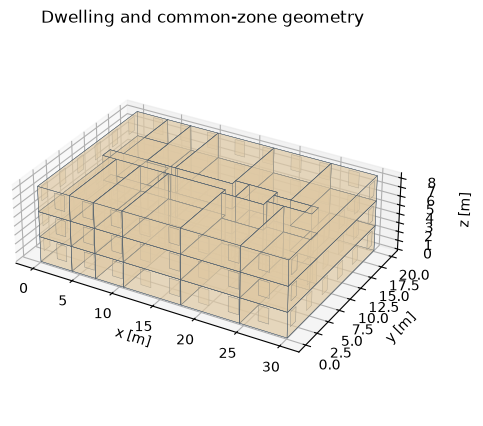

In [2]:
b=building()
b=b.updated(facade=b.facade.updated(layout=WindowLayoutSpec(mode="wwr")),use=b.use.updated(occupancy_category="residential"),envelope=b.envelope.updated(dwelling_partition=b.envelope.intermediate_floor,common_partition=b.envelope.intermediate_floor),geometry=b.geometry.updated(zoning=ZoningSpec(mode="apartments")))
common=b.use.updated(heating_setpoint=ScheduleSpec.constant(18),occupant_density_per_m2=0,equipment_gain_w_m2=0,lighting_gain_w_m2=1,dhw_kwh_m2_year=0)
b=b.updated(common_use=common,common_airflow=AirflowSpec(topology="F",envelope_infiltration_ach=.1,mechanical_vent_l_s_m2=.2))
table({"dwelling_setpoint_C":b.use.heating_setpoint.values[0],"common_setpoint_C":b.common_use.heating_setpoint.values[0],"conserve_residential_loads":b.geometry.zoning.apartments.conserve_residential_loads})
preview(b,"Dwelling and common-zone geometry")

## Compare daily control temperatures

A lower circulation temperature is an illustrative operation, not a universal rule for residential stocks.

### Read the code and output

Both plotted temperatures are setpoints. Whether every zone reaches them is an engine result, not a property of the input curve. The lighting bars have units of W/m² of the relevant role area; compare achieved role areas before translating them into whole-building power.

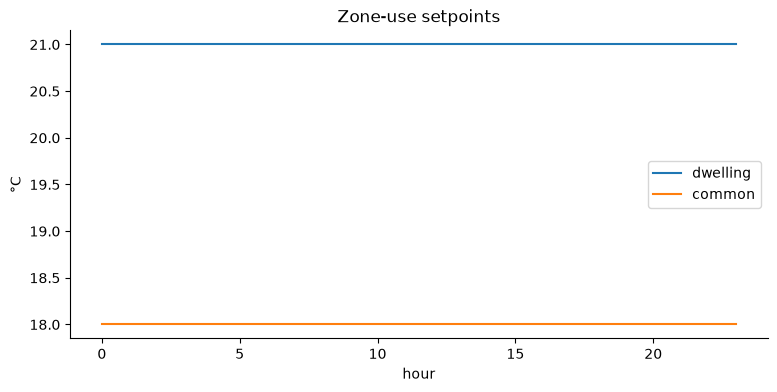

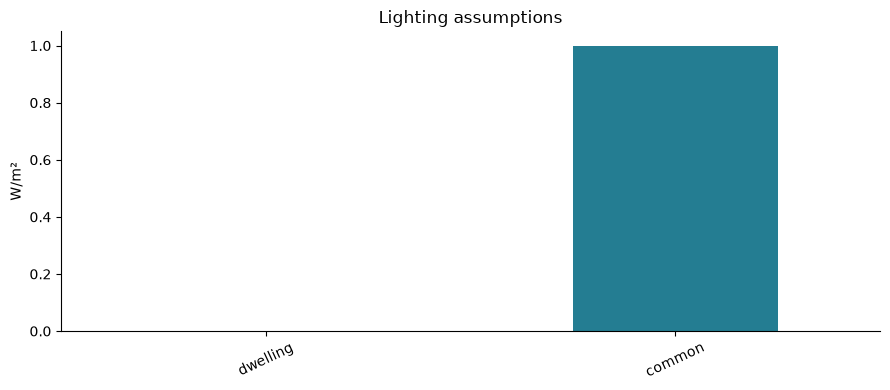

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
pd.DataFrame({"dwelling":b.use.heating_setpoint.values,"common":common.heating_setpoint.values}).plot(ax=ax, ylabel="°C",xlabel="hour",title="Zone-use setpoints"); plt.show(); plt.close(fig)
bars({"dwelling":b.use.lighting_gain_w_m2,"common":common.lighting_gain_w_m2},"W/m²","Lighting assumptions")

## Inspect actual compiled assignments

Read the generated zones and layout report rather than assuming that target type shares uniquely determine the common-area fraction.

### Read the code and output

The compilation report lists generated zones and the achieved layout. Confirm the effective zoning mode before calling this a dwelling/common-space comparison. A fallback to per-storey would represent a different model and should not be included under the requested apartment label.

In [4]:
model,report=EnergyPlusCompiler(engine()).compile(b)
table(report.data["layout"])
assert report.data["zoning"]["effective_mode"]=="apartments"
table(pd.DataFrame.from_dict(report.data["zones"],orient="index").reset_index())

,field,value
0,achieved_unit_counts,"{'2rok': 12, '3rok': 3, '4rok': 3, 'studio': 12}"
1,assumptions,"{'common_heating_setpoint_c': 18.0, 'conserve_..."
2,parts,"[{'candidates': 333, 'part_id': 'main', 'reaso..."
3,status,generated


,index,conditioned,elevations_m,floor_area_m2,part_ids,volume_m3,zone_kind,apartment_type
0,main_main_0_common_10,True,"[0.0, 2.8]",27.875,[main],78.05,common,NaN
1,main_main_0_common_11,True,"[0.0, 2.8]",7.875,[main],22.05,common,NaN
2,main_main_0_dwelling_0,True,"[0.0, 2.8]",77.375,[main],216.65,dwelling,3rok
3,main_main_0_dwelling_1,True,"[0.0, 2.8]",27.750,[main],77.70,dwelling,studio
4,main_main_0_dwelling_2,True,"[0.0, 2.8]",27.750,[main],77.70,dwelling,studio
5,main_main_0_dwelling_3,True,"[0.0, 2.8]",32.375,[main],90.65,dwelling,studio
6,main_main_0_dwelling_4,True,"[0.0, 2.8]",32.375,[main],90.65,dwelling,studio
7,main_main_0_dwelling_5,True,"[0.0, 2.8]",64.750,[main],181.30,dwelling,2rok
8,main_main_0_dwelling_6,True,"[0.0, 2.8]",64.750,[main],181.30,dwelling,2rok
9,main_main_0_dwelling_7,True,"[0.0, 2.8]",61.000,[main],170.80,dwelling,2rok


,index,conditioned,elevations_m,floor_area_m2,part_ids,volume_m3,zone_kind,apartment_type
0,main_main_0_common_10,True,"[0.0, 2.8]",27.875,[main],78.05,common,NaN
1,main_main_0_common_11,True,"[0.0, 2.8]",7.875,[main],22.05,common,NaN
2,main_main_0_dwelling_0,True,"[0.0, 2.8]",77.375,[main],216.65,dwelling,3rok
3,main_main_0_dwelling_1,True,"[0.0, 2.8]",27.750,[main],77.70,dwelling,studio
4,main_main_0_dwelling_2,True,"[0.0, 2.8]",27.750,[main],77.70,dwelling,studio
5,main_main_0_dwelling_3,True,"[0.0, 2.8]",32.375,[main],90.65,dwelling,studio
6,main_main_0_dwelling_4,True,"[0.0, 2.8]",32.375,[main],90.65,dwelling,studio
7,main_main_0_dwelling_5,True,"[0.0, 2.8]",64.750,[main],181.30,dwelling,2rok
8,main_main_0_dwelling_6,True,"[0.0, 2.8]",64.750,[main],181.30,dwelling,2rok
9,main_main_0_dwelling_7,True,"[0.0, 2.8]",61.000,[main],170.80,dwelling,2rok


## Interpretation and next experiment

Physical apartment partitions and different common-space operations change the modelling package. They are not equivalent to virtual perimeter/core zoning.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.